# EDA: Rock / Paper / Scissors z HaGRID (`dataset/hagrid_user_split`)

## Opis ogólny

Projekt to klasyfikator gestów do gry w papier–kamień–nożyce model dostaje zdjęcie dłoni i rozpoznaje jeden z trzech
gestów. Dane pochodzą ze zbioru HaGRID (Hand Gesture Recognition Image Dataset), czyli dużego zbioru zdjęć gestów dłoni
nagranych przez tysiące osób własnymi kamerami i telefonami, w domach i biurach, przy różnym oświetleniu i tle.
Korzystamy z wersji `cj-mills/hagrid-classification-512p-no-gesture-150k` (Hugging Face), gdzie każde zdjęcie
jest już wycinkiem wokół dłoni przeskalowanym do maks. 512 px. Model wykrywa gesty `fist → rock`, `palm → paper`, `peace → scissors`.

Celem tego notebooka jest sprawdzić, czy zbiór nadaje się do trenowania i oceny modelu, czyli czy jest zrównoważony,
czysty, bez skrótów (cech zdradzających klasę poza samym gestem) i bez wycieku danych między train a test.

## Konfiguracja

In [20]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score


def find_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("Nie znaleziono pyproject.toml")


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "dataset" / "hagrid_user_split"
OUT_DIR = ROOT / "outputs" / "eda" / DATA_DIR.name
OUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]
CLASSES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
SEED = 42

sns.set_theme(style="whitegrid")
PALETTE = dict(zip(CLASSES, sns.color_palette("tab10", len(CLASSES))))
pd.set_option("display.precision", 3)

info = json.loads((DATA_DIR / "dataset_info.json").read_text(encoding="utf-8"))
split_csv = pd.read_csv(DATA_DIR / "split.csv")
print(DATA_DIR.relative_to(ROOT), CLASSES)
print({k: info[k] for k in ("source", "label_map", "per_class", "val_ratio", "test_ratio", "group_by",
                            "n_users", "n_groups", "seed")})

dataset\hagrid_user_split ['paper', 'rock', 'scissors']
{'source': 'hf:cj-mills/hagrid-classification-512p-no-gesture-150k', 'label_map': {'rock': 'fist', 'paper': 'palm', 'scissors': 'peace'}, 'per_class': 6870, 'val_ratio': 0.15, 'test_ratio': 0.15, 'group_by': 'user', 'n_users': 6225, 'n_groups': 6184, 'seed': 42}


**Wniosek**

Dataset hagrid_user_split ma 3 klasy (`paper`, `rock`, `scissors`). Zbudowano go z `per_class = 6870`, podział 70/15/15 po osobach (`group_by = user`), 6225 osób i 6184 grup.

## 0. Wczytanie zdjęć i podstawowe statystyki

In [19]:
records, thumbs = [], []
files = [(s, c, f) for s in SPLITS for c in CLASSES for f in sorted((DATA_DIR / s / c).iterdir())]
for split, label, f in files:
    raw = f.read_bytes()
    rec = {"split": split, "label": label, "file": f.name, "path": f"{split}/{label}/{f.name}",
           "bytes": len(raw), "md5": hashlib.md5(raw).hexdigest(), "error": None}
    try:
        img = Image.open(f)
        rec.update(width=img.width, height=img.height, mode=img.mode, format=img.format)
        rgb = np.asarray(img.convert("RGB"), dtype=np.float32)
        rec.update(mean_r=rgb[..., 0].mean(), mean_g=rgb[..., 1].mean(), mean_b=rgb[..., 2].mean(),
                   brightness=rgb.mean(), contrast=rgb.mean(2).std())
        thumbs.append(np.asarray(img.convert("L").resize((48, 32), Image.BILINEAR), dtype=np.float32).ravel())
    except Exception as e:  #noqa: BLE001
        rec["error"] = repr(e)
        thumbs.append(np.zeros(48 * 32, dtype=np.float32))
    records.append(rec)

df = pd.DataFrame(records)
df["aspect"] = df["width"] / df["height"]
df = df.merge(split_csv[["path", "user_id", "group", "group_size"]], on="path", how="left", validate="1:1")
thumbs = np.stack(thumbs)
print(len(df), "obrazów,", df["user_id"].isna().sum(), "bez user_id")

20610 obrazów, 0 bez user_id


**Wniosek:** Udało się wczytać wszystkie 20 610 zdjęć i do każdego z nich znaleźć osobę, bez ani jednego braku.

## 1. Liczba zdjęć na klasę i podzbiór (train / val / test)

Tabela liczności i udział każdego podzbioru.

In [37]:
counts = pd.crosstab(df["split"], df["label"], margins=True, margins_name="razem").reindex([*SPLITS, "razem"])
counts["udział"] = (counts["razem"] / len(df)).round(3)
display(counts)

expected = pd.DataFrame(info["counts"]).T.reindex(SPLITS)[CLASSES]
assert (counts.loc[SPLITS, CLASSES].values == expected.values).all(), "liczności różnią się od dataset_info.json"
assert set(df["path"]) == set(split_csv["path"]), "pliki na dysku różnią się od split.csv"

label,paper,rock,scissors,razem,udział
split,,,,,
train,4908,4909,4908,14725,0.714
val,982,981,982,2945,0.143
test,980,980,980,2940,0.143
razem,6870,6870,6870,20610,1.000


**Wniosek:** Klasy są rozłożone praktycznie idealnie równo. Do treningu trafiło 14 725 zdjęć, a do walidacji i testu po około 2 940. Train jest odrobinę większy niż zakładane 70%, bo dzielimy całe osoby, a nie pojedyncze zdjęcia, więc proporcji nie da się trafić co do zdjęcia.

Porównanie z pełnym zbiorem na Hugging Face.

,HF (fist/palm/peace),w datasecie,odrzucone (brak user_id + balansowanie)
paper,7050,6870,180
rock,6882,6870,12
scissors,6965,6870,95


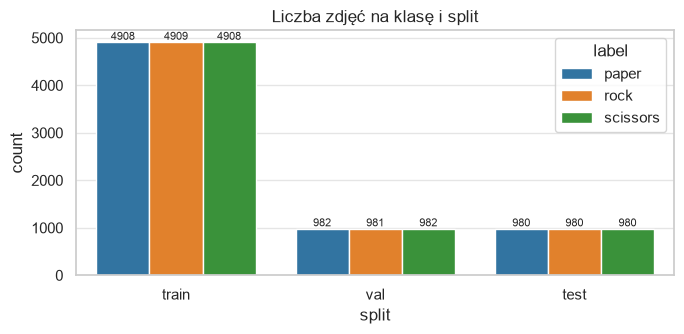

In [22]:
HF_COUNTS = {"rock": 6882, "paper": 7050, "scissors": 6965}
summary = pd.DataFrame({"HF (fist/palm/peace)": HF_COUNTS, "w datasecie": df["label"].value_counts()}).loc[CLASSES]
summary["odrzucone (brak user_id + balansowanie)"] = summary.iloc[:, 0] - summary.iloc[:, 1]
display(summary)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(data=df, x="split", hue="label", order=SPLITS, palette=PALETTE, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
ax.set_title("Liczba zdjęć na klasę i split")
fig.tight_layout(); fig.savefig(OUT_DIR / "class_counts.png", dpi=150); plt.show()

**Wniosek:** W porównaniu z pełnym zbiorem na Hugging Face straciliśmy niewiele 180 zdjęć „paper”, 95 „scissors” i 12 „rock”, czyli około 1,4%. Część z nich nie miała przypisanej osoby, a resztę odrzuciliśmy, żeby wyrównać klasy. D

## 2. Osoby i podział po osobach

Najważniejsze założenie tego zbioru jest takie, że każda osoba trafia tylko do jednego podzbioru albo do treningu, albo do walidacji, albo do testu. Sprawdzamy, czy to założenie naprawdę jest spełnione, czyli czy żadna osoba nie pojawia się w dwóch podzbiorach naraz. Przy okazji liczymy, ile osób jest w każdym podzbiorze, ile zdjęć przypada średnio na jedną osobę i ile różnych gestów pokazuje każda z nich.

In [38]:
users = {s: set(df.loc[df["split"] == s, "user_id"]) for s in SPLITS}
overlap = pd.DataFrame({a: {b: len(users[a] & users[b]) for b in SPLITS} for a in SPLITS})
display(overlap.rename_axis("wspólne osoby"))
assert all(overlap.loc[a, b] == 0 for a in SPLITS for b in SPLITS if a != b), "ta sama osoba w dwóch splitach"
groups = {s: set(df.loc[df["split"] == s, "group"]) for s in SPLITS}
assert all(not (groups[a] & groups[b]) for a in SPLITS for b in SPLITS if a < b), "grupa w dwóch splitach"

per_user = df.groupby("user_id").agg(split=("split", "first"), n_img=("path", "size"), n_classes=("label", "nunique"))
display(per_user.groupby("split").agg(osoby=("n_img", "size"), zdjęć_na_osobę_śr=("n_img", "mean"),
                                       zdjęć_na_osobę_max=("n_img", "max")).reindex(SPLITS).round(2))
display(per_user["n_classes"].value_counts().sort_index().rename_axis("ile różnych gestów u osoby").to_frame("osoby"))

,train,val,test
wspólne osoby,,,
train,4339,0,0
val,0,946,0
test,0,0,940


,osoby,zdjęć_na_osobę_śr,zdjęć_na_osobę_max
split,,,
train,4339,3.39,62
val,946,3.11,47
test,940,3.13,61


,osoby
ile różnych gestów u osoby,
1,3816
2,1291
3,1118


**Wniosek:** Żadna osoba nie występuje w więcej niż jednym podzbiorze i nie mają one ani jednej wspólnej osoby. Jedna osoba ma średnio nieco ponad 3 zdjęcia. Co ważne, ponad 2 400 osób pokazuje dwa albo trzy różne gesty, więc model nie może się nauczyć skrótu w stylu „ta osoba zawsze pokazuje kamień”.

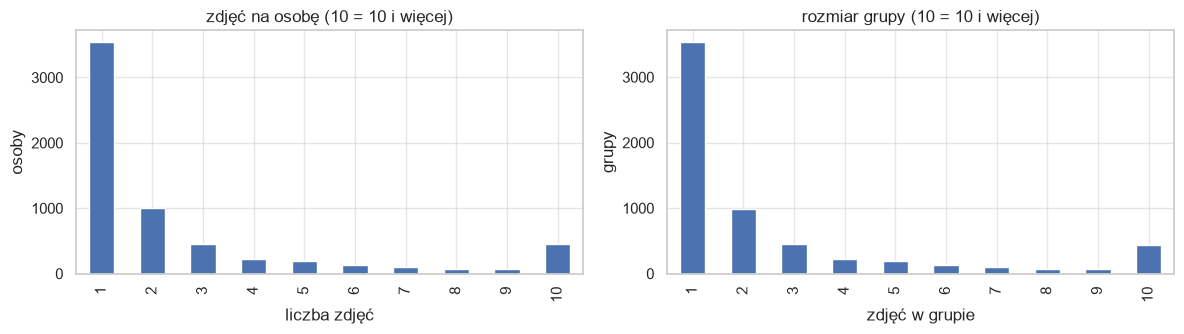

największa grupa: 319 zdjęć


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
per_user["n_img"].clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("zdjęć na osobę (10 = 10 i więcej)"); axes[0].set_xlabel("liczba zdjęć"); axes[0].set_ylabel("osoby")
gs = df.drop_duplicates("group")["group_size"]
gs.clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("rozmiar grupy (10 = 10 i więcej)"); axes[1].set_xlabel("zdjęć w grupie"); axes[1].set_ylabel("grupy")
fig.tight_layout(); fig.savefig(OUT_DIR / "users_groups.png", dpi=150); plt.show()
print("największa grupa:", gs.max(), "zdjęć")

**Wniosek:** Większość osób i grup ma tylko 1–3 zdjęcia, więc nikt nie dominuje w zbiorze. Wyróżnia się jedna grupa liczącą 319 zdjęć (około 1,5% danych). Powstała, bo przy grupowaniu podobnych klatek kilka osób z podobnym tłem połączyło się w jeden łańcuch.

## 3. Integralność plików i rozmiary

Sprawdzamy, czy wszystkie pliki dają się otworzyć i w jakim są formacie. Porównujemy też wymiary zdjęć, ich proporcje i wagę plików między klasami, żeby zobaczyć, czy któraś klasa nie odstaje od pozostałych.

In [25]:
print("uszkodzone pliki:", df["error"].notna().sum())
display(df[["mode", "format"]].value_counts().to_frame("n"))
display(df.groupby("label")[["width", "height", "aspect", "bytes"]].describe().T.round(2))

uszkodzone pliki: 0


,,n
mode,format,
RGB,JPEG,20610


label            paper      rock  scissors
width  count   6870.00   6870.00   6870.00
       mean     507.16    504.42    503.39
       std       21.37     27.23     30.05
       min      294.00    176.00    155.00
       25%      512.00    512.00    512.00
       50%      512.00    512.00    512.00
       75%      512.00    512.00    512.00
       max      512.00    512.00    512.00
height count   6870.00   6870.00   6870.00
       mean     508.45    507.93    508.25
       std       20.19     21.71     21.79
       min      240.00    144.00    206.00
       25%      512.00    512.00    512.00
       50%      512.00    512.00    512.00
       75%      512.00    512.00    512.00
       max      512.00    512.00    512.00
aspect count   6870.00   6870.00   6870.00
       mean       1.00      0.99      0.99
       std        0.05      0.06      0.06
       min        0.58      0.53      0.48
       25%        1.00      1.00      1.00
       50%        1.00      1.00      1.00
       75%        1.00      1.00      1.00
       max        1.80      1.87      1.71
bytes  count   6870.00   6870.00   6870.00
       mean   24276.33  23538.85  24200.79
       std     7552.53   7916.41   7787.60
       min     8635.00   4479.00   5576.00
       25%    19132.25  18143.00  18868.75
       50%    23205.50  22454.00  23114.00
       75%    28005.25  27460.75  28240.75
       max    72571.00  77543.00  78778.00

**Wniosek:** Wszystkie pliki dają się poprawnie otworzyć i wszystkie są kolorowymi JPEG-ami.

Te same wymiary pokazane na wykresach. Gdyby zdjęcia jednej klasy miały wyraźnie inny rozmiar niż pozostałe, model mógłby rozpoznawać klasę po rozmiarze zamiast po geście.

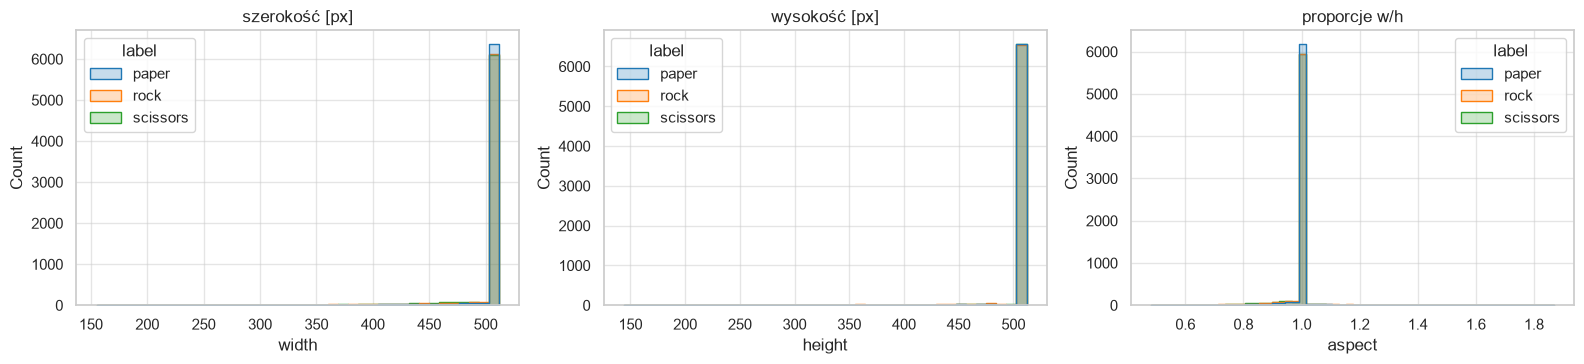

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(data=df, x="width", hue="label", palette=PALETTE, element="step", bins=40, ax=axes[0])
sns.histplot(data=df, x="height", hue="label", palette=PALETTE, element="step", bins=40, ax=axes[1])
sns.histplot(data=df, x="aspect", hue="label", palette=PALETTE, element="step", bins=60, ax=axes[2])
axes[0].set_title("szerokość [px]"); axes[1].set_title("wysokość [px]"); axes[2].set_title("proporcje w/h")
fig.tight_layout(); fig.savefig(OUT_DIR / "sizes.png", dpi=150); plt.show()

**Wniosek:** Zdecydowana większość zdjęć jest kwadratowa i ma 512×512 pikseli. Mniejsze zdjęcia, wycięte przy krawędzi kadru, zdarzają się rzadko i podobnie często w każdej klasie. Sam rozmiar zdjęcia nie mówi więc nic o pokazanym geście.

### 3a. Czy sam rozmiar zdradza klasę?

Zdjęcia są wycięte wokół dłoni, więc ich kształt może zależeć od gestu, np. otwarta dłoń daje szerszy kadr, a nożyce wyższy. Przed podaniem do modelu każde zdjęcie jest rozciągane do kwadratu 224×224, więc taka informacja częściowo w nim zostaje. Żeby sprawdzić, czy to realny problem, uczymy prosty klasyfikator, który widzi tylko wymiary, wagę pliku i średni kolor, bez patrzenia na to, co jest na zdjęciu. Jeśli wynik będzie bliski zgadywania (33%), te cechy nie zdradzają klasy.

In [27]:
def shortcut_acc(cols):
    tr, te = df[df["split"] == "train"], df[df["split"] == "test"]
    clf = HistGradientBoostingClassifier(random_state=SEED).fit(tr[cols], tr["label"])
    return accuracy_score(te["label"], clf.predict(te[cols]))

shortcuts = pd.Series({
    "losowo": 1 / len(CLASSES),
    "width, height, aspect": shortcut_acc(["width", "height", "aspect"]),
    "bytes": shortcut_acc(["bytes"]),
    "średni kolor + jasność + kontrast": shortcut_acc(["mean_r", "mean_g", "mean_b", "brightness", "contrast"]),
    "wszystko powyżej": shortcut_acc(["width", "height", "aspect", "bytes", "mean_r", "mean_g", "mean_b",
                                      "brightness", "contrast"]),
}, name="test accuracy")
display(shortcuts.to_frame())

,test accuracy
losowo,0.333
"width, height, aspect",0.339
bytes,0.338
średni kolor + jasność + kontrast,0.352
wszystko powyżej,0.369


**Wniosek:** Model, który widzi tylko rozmiar zdjęcia, jego proporcje, wagę pliku i średni kolor, trafia w 34–37% przypadków. To niewiele więcej niż zgadywanie (33%). Oznacza to, że te cechy prawie nic nie mówią o klasie, więc prawdziwy model musi patrzeć na samą dłoń, a nie na takie skróty.

## 4. Przykładowe obrazy

Pokazujemy po 8 losowych zdjęć z treningu dla każdej klasy, żeby zobaczyć, jak wyglądają dane.

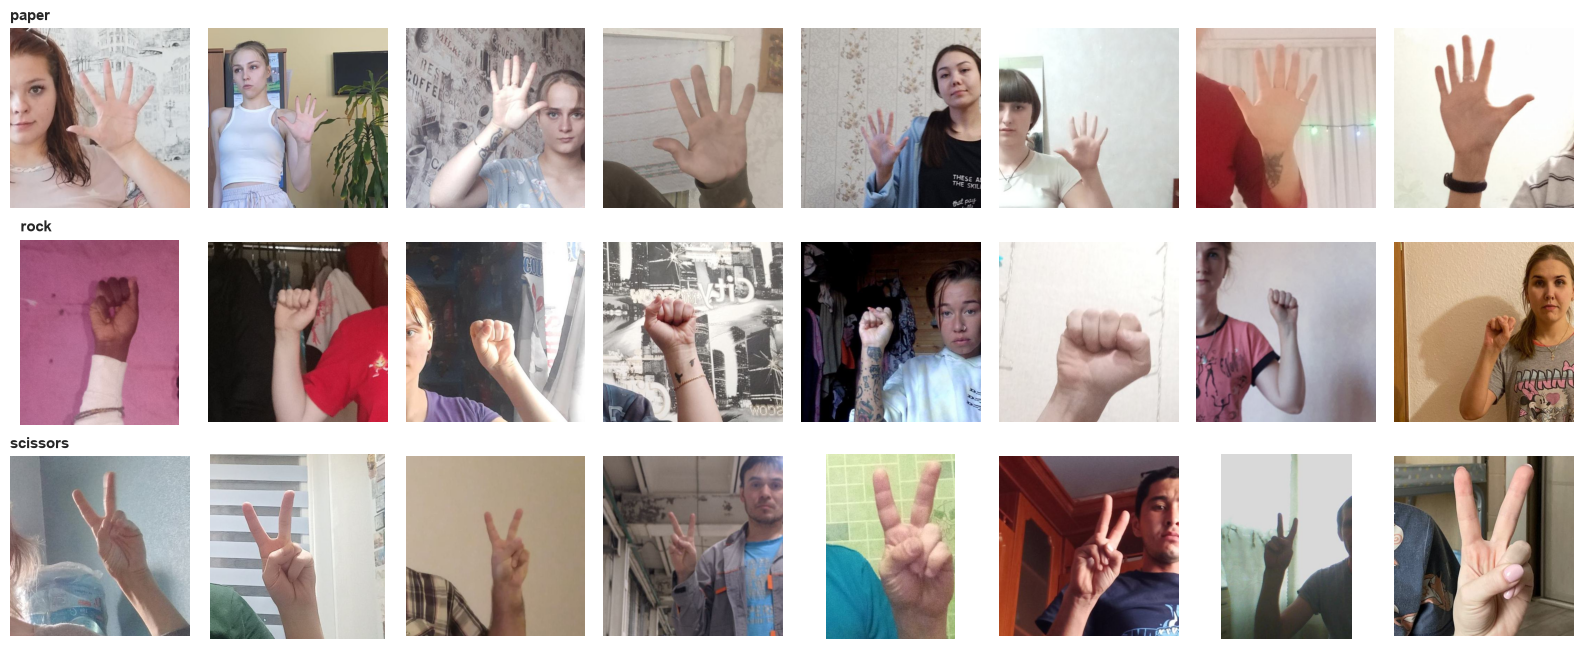

In [28]:
n = 8
fig, axes = plt.subplots(len(CLASSES), n, figsize=(2 * n, 2.2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    sample = df[(df["label"] == c) & (df["split"] == "train")].sample(n, random_state=SEED)
    for j, (ax, p) in enumerate(zip(axes[i], sample["path"])):
        ax.imshow(Image.open(DATA_DIR / p)); ax.axis("off")
        if j == 0:
            ax.set_title(c, loc="left", fontsize=11, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT_DIR / "samples.png", dpi=120); plt.show()

**Wniosek:** Zdjęcia są bardzo zróżnicowane: różni ludzie, różne pokoje i tapety, różne oświetlenie i odległość od kamery. Dłoń zwykle jest na środku, ale często w kadrze widać też twarz i tułów, a gesty są pokazywane pod różnymi kątami. To dobrze, bo model uczy się na warunkach podobnych do prawdziwych.

Porównujemy jasność, kontrast i kolorystykę zdjęć w każdej klasie. Gdyby np. zdjęcia „kamienia” były zwykle ciemniejsze, model mógłby uczyć się oświetlenia zamiast gestu.

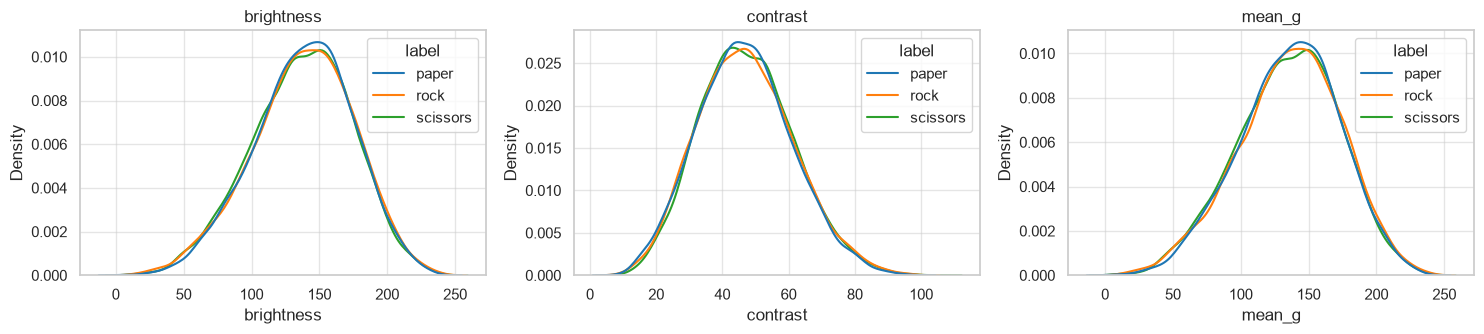

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["brightness", "contrast", "mean_g"]):
    sns.kdeplot(data=df, x=col, hue="label", palette=PALETTE, common_norm=False, ax=ax)
    ax.set_title(col)
fig.tight_layout(); fig.savefig(OUT_DIR / "color_stats.png", dpi=150); plt.show()

**Wniosek:** Jasność, kontrast i kolorystyka zdjęć wyglądają tak samo we wszystkich trzech klasach, wykresy niemal się pokrywają. Nie ma więc sytuacji, w której na przykład zdjęcia kamienia byłyby zawsze ciemniejsze.

## 5. Wyciek między podzbiorami

### 5a. Dokładne duplikaty

Wyciek oznacza, że model w teście widzi zdjęcia, które już znał z treningu, przez co wynik wychodzi lepszy niż w rzeczywistości. Najpierw szukamy identycznych plików każdemu liczymy sumę kontrolną MD5 i sprawdzamy, czy ten sam plik nie występuje dwa razy, zwłaszcza w różnych podzbiorach albo z różnymi etykietami.

In [39]:
dup = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("obrazów z duplikatem MD5:", len(dup), "| grup:", dup["md5"].nunique())
cross = dup.groupby("md5").agg(splits=("split", lambda s: tuple(sorted(set(map(str, s))))),
                               labels=("label", lambda s: tuple(sorted(set(s)))))
print("grupy MD5 rozdzielone między splity:", (cross["splits"].map(len) > 1).sum())
print("grupy MD5 z różnymi etykietami:", (cross["labels"].map(len) > 1).sum())
display(dup.head(10)[["path", "md5", "bytes"]])

obrazów z duplikatem MD5: 0 | grup: 0
grupy MD5 rozdzielone między splity: 0
grupy MD5 z różnymi etykietami: 0


,path,md5,bytes


**Wniosek:** W zbiorze nie ma ani jednego zdublowanego pliku, ani w obrębie jednego podzbioru, ani między podzbiorami.

### 5b. Bardzo podobne zdjęcia między testem a treningiem

Identyczne pliki to tylko część problemu. Często zdarzają się zdjęcia prawie takie same, np. kolejne klatki tego samego nagrania. Dlatego dla każdego zdjęcia z testu szukamy najbardziej podobnego zdjęcia w treningu i mierzymy to podobieństwo na dwa sposoby:
- piksele: porównujemy małe, szare miniatury zdjęć,
- cechy z sieci: porównujemy to, co „widzi” gotowa sieć MobileNetV3. Ta miara wyłapuje też to samo ujęcie po przesunięciu lub przeskalowaniu, a także tę samą osobę czy to samo tło.

Dla porównania szukamy też najbardziej podobnego zdjęcia w samym teście. Jeśli zdjęcia z testu są dużo bardziej podobne do treningu niż do siebie nawzajem, to sygnał, że coś przeciekło. Zaczynamy od pikseli:

In [31]:
def normalize(x, center=False):
    if center:  #Pearson = cosinus po odjęciu średniej
        x = x - x.mean(1, keepdims=True)
    return x / np.linalg.norm(x, axis=1, keepdims=True).clip(1e-8)

def nearest(query, base, exclude_self=False, chunk=2048):
    best_sim, best_idx = np.empty(len(query)), np.empty(len(query), dtype=int)
    for s in range(0, len(query), chunk):
        sim = query[s:s + chunk] @ base.T
        if exclude_self:
            sim[np.arange(sim.shape[0]), np.arange(s, s + sim.shape[0])] = -np.inf
        best_idx[s:s + chunk] = sim.argmax(1)
        best_sim[s:s + chunk] = sim.max(1)
    return best_sim, best_idx

idx = {s: np.flatnonzero(df["split"] == s) for s in SPLITS}
T = normalize(thumbs, center=True)
px_tt_sim, px_tt_idx = nearest(T[idx["test"]], T[idx["train"]])
px_te_sim, _ = nearest(T[idx["test"]], T[idx["test"]], exclude_self=True)

Teraz przepuszczamy wszystkie zdjęcia przez sieć MobileNetV3 wytrenowaną na ImageNet (bez douczania na naszych danych) i zapisujemy dla każdego jego opis liczbowy. Zdjęcia przygotowujemy tak samo jak przy ocenie modelu. Na karcie graficznej trwa to kilkadziesiąt sekund, na procesorze kilka minut.

In [32]:
import torch
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

from src.transforms import build_transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
backbone = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
backbone.classifier = torch.nn.Identity()
backbone.eval().to(device)
tf = build_transforms(224)

embs = []
with torch.no_grad():
    for s in range(0, len(df), 256):
        batch = torch.stack([tf(Image.open(DATA_DIR / p).convert("RGB")) for p in df["path"].iloc[s:s + 256]])
        embs.append(backbone(batch.to(device)).cpu().numpy())
E = normalize(np.concatenate(embs))
cnn_tt_sim, cnn_tt_idx = nearest(E[idx["test"]], E[idx["train"]])
cnn_te_sim, _ = nearest(E[idx["test"]], E[idx["test"]], exclude_self=True)
print(device, E.shape)

cuda (20610, 576)


Na wykresach porównujemy, jak podobne jest każde zdjęcie z testu do najbliższego zdjęcia z treningu i do najbliższego innego zdjęcia z testu. Tabela pokazuje, jaki procent zdjęć z testu ma „sąsiada” podobniejszego niż dany próg.

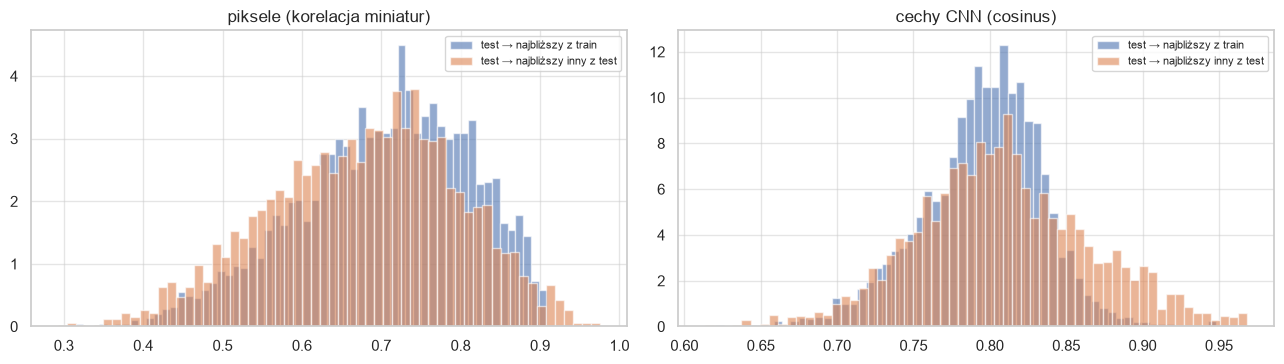

,piksele test→train,piksele test→test,CNN test→train,CNN test→test
>= 0.9,0.51,1.94,0.51,6.39
>= 0.95,0.00,0.14,0.00,0.85
>= 0.98,0.00,0.00,0.00,0.00
>= 0.99,0.00,0.00,0.00,0.00


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, tt, te) in zip(axes, [("piksele (korelacja miniatur)", px_tt_sim, px_te_sim),
                                     ("cechy CNN (cosinus)", cnn_tt_sim, cnn_te_sim)]):
    ax.hist(tt, bins=60, alpha=0.6, label="test → najbliższy z train", density=True)
    ax.hist(te, bins=60, alpha=0.6, label="test → najbliższy inny z test", density=True)
    ax.set_title(name); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "nearest_neighbor_similarity.png", dpi=150); plt.show()

thresholds = [0.90, 0.95, 0.98, 0.99]
display(pd.DataFrame({
    "piksele test→train": [(px_tt_sim >= t).mean() for t in thresholds],
    "piksele test→test": [(px_te_sim >= t).mean() for t in thresholds],
    "CNN test→train": [(cnn_tt_sim >= t).mean() for t in thresholds],
    "CNN test→test": [(cnn_te_sim >= t).mean() for t in thresholds],
}, index=[f">= {t}" for t in thresholds]).mul(100).round(2))  #% zdjęć z testu z sąsiadem powyżej progu

**Wniosek:** Zdjęcia z testu są bardziej podobne do siebie nawzajem niż do zdjęć z treningu. Bardzo podobnego „sąsiada” w treningu ma tylko 0,5% zdjęć z testu, a w samym teście aż 6,4%. Tak właśnie powinno być przy podziale po osobach: zdjęcia jednej osoby trzymają się razem w jednym podzbiorze. Prawie identycznych zdjęć między testem a treningiem nie ma wcale, więc nie widać śladów wycieku.

Oglądamy 10 par zdjęć z testu i treningu, które sieć uznała za najbardziej podobne.

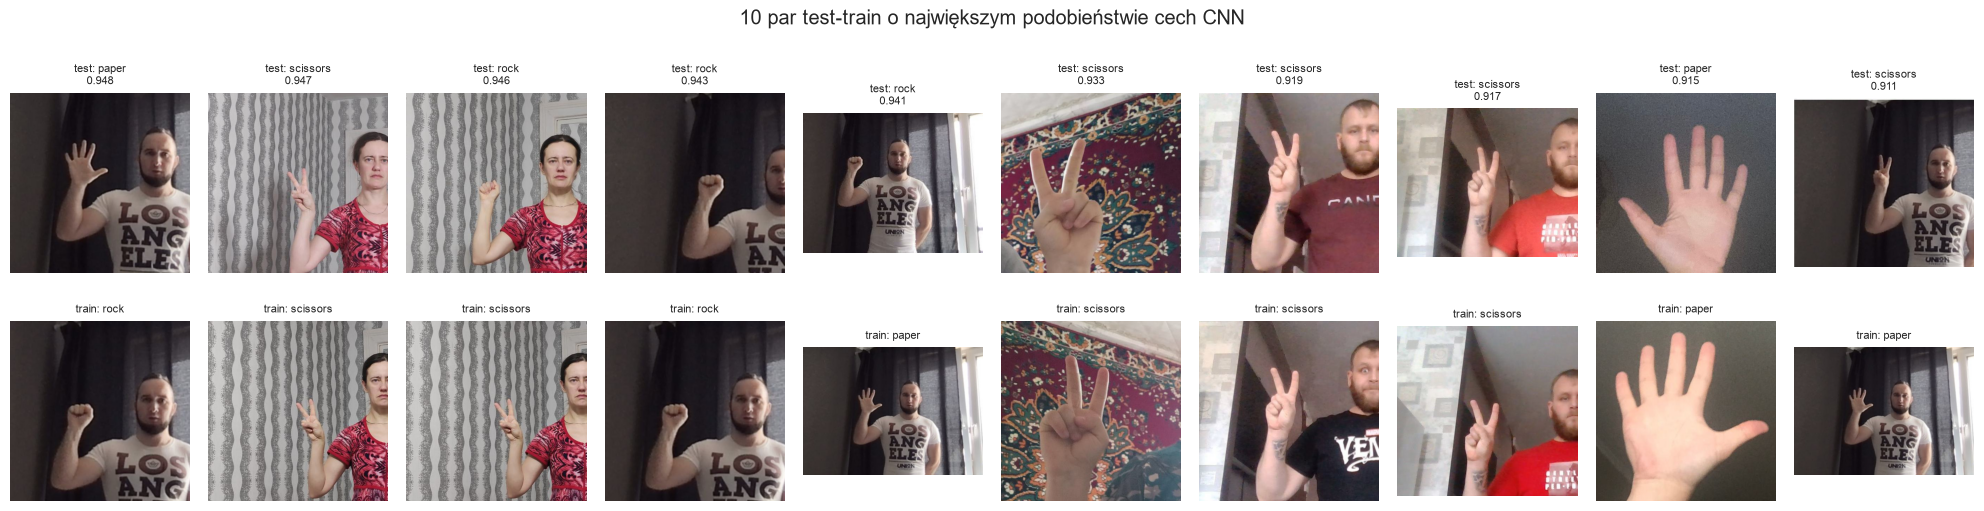

In [34]:
order = np.argsort(-cnn_tt_sim)[:10]
fig, axes = plt.subplots(2, 10, figsize=(20, 5.6))
for j, k in enumerate(order):
    a, b = df.iloc[idx["test"][k]], df.iloc[idx["train"][cnn_tt_idx[k]]]
    assert a["user_id"] != b["user_id"]
    axes[0, j].imshow(Image.open(DATA_DIR / a["path"])); axes[0, j].set_title(f"test: {a['label']}\n{cnn_tt_sim[k]:.3f}", fontsize=8)
    axes[1, j].imshow(Image.open(DATA_DIR / b["path"])); axes[1, j].set_title(f"train: {b['label']}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("10 par test-train o największym podobieństwie cech CNN")
fig.tight_layout(); fig.savefig(OUT_DIR / "top_test_train_pairs.png", dpi=120); plt.show()

**Wniosek:** Wśród najbardziej podobnych par widać, że czasem to ta sama osoba w tym samym pokoju i ubraniu (np. mężczyzna w koszulce „LOS ANGELES” albo kobieta w czerwonej bluzce), mimo że ma inny `user_id`. Wygląda na to, że w HaGRID niektóre osoby nagrywały pod kilkoma identyfikatorami. Na szczęście w takich parach gesty często się różnią (np. w teście „kamień”, w treningu „nożyce”), więc model nie może po prostu rozpoznać osoby i zgadnąć gestu.

### 5c. Jak trudne jest zadanie bez uczenia?

Sprawdzamy najprostszą możliwą metodę, każde zdjęcie z testu dostaje etykietę najbardziej podobnego zdjęcia z treningu, bez żadnego uczenia. Jeśli już to daje wynik bliski 100%, zadanie jest banalne albo dane przeciekają. Jeśli wynik jest wyraźnie niższy, wysoka dokładność naszego modelu oznacza, że naprawdę nauczył się rozpoznawać gesty.

In [35]:
y = df["label"].to_numpy()
knn_acc = (y[idx["train"]][cnn_tt_idx] == y[idx["test"]]).mean()
px_knn_acc = (y[idx["train"]][px_tt_idx] == y[idx["test"]]).mean()
print(f"1-NN na cechach MobileNetV3 (ImageNet, bez fine-tuningu): test accuracy = {knn_acc:.4f}")
print(f"1-NN na miniaturach pikseli:                              test accuracy = {px_knn_acc:.4f}")

1-NN na cechach MobileNetV3 (ImageNet, bez fine-tuningu): test accuracy = 0.6980
1-NN na miniaturach pikseli:                              test accuracy = 0.4422


**Wniosek:** Najprostsza metoda bez żadnego uczenia, czyli przypisanie zdjęciu etykiety najbardziej podobnego zdjęcia z treningu, daje 70% na cechach z gotowej sieci i 44% na samych pikselach. Zadanie nie jest więc trywialne, a wysoki wynik wytrenowanego modelu oznacza, że naprawdę nauczył się rozpoznawać gesty, a nie zapamiętał podobne zdjęcia.

Na koniec sprawdzamy, czy bardzo podobne pary test–trening zwykle pokazują ten sam gest. Gdyby tak było, i to dużo częściej niż w przypadku mniej podobnych par, model mógłby rozpoznawać osobę lub tło zamiast samego gestu.

In [36]:
same = y[idx["train"]][cnn_tt_idx] == y[idx["test"]]
bins = pd.cut(cnn_tt_sim, [0, 0.8, 0.85, 0.9, 1.0])
display(pd.DataFrame({"obrazów z testu": pd.Series(bins).value_counts().sort_index(),
                      "ta sama etykieta co sąsiad z train [%]": pd.Series(same).groupby(bins, observed=False).mean().mul(100).round(1)}))

,obrazów z testu,ta sama etykieta co sąsiad z train [%]
"(0.0, 0.8]",1515,65.7
"(0.8, 0.85]",1245,72.9
"(0.85, 0.9]",165,85.5
"(0.9, 1.0]",15,53.3


**Wniosek:** Im bardziej zdjęcia są do siebie podobne, tym częściej pokazują ten sam gest (od 66% do 86%), co jest naturalne, bo podobny kształt dłoni to zwykle ten sam gest. Ciekawe jest to, że dla najbardziej podobnych par, czyli tej samej osoby lub tego samego tła, zgodność spada do 53%. Takich zdjęć jest w teście tylko 15 (0,5%), więc osoby z kilkoma identyfikatorami nie wpływają zauważalnie na wynik.